# Severstal: Steel Defect Detection

Steel is one of the most important building materials of modern times. Steel buildings are resistant to natural and man-made wear which has made the material ubiquitous around the world. To help make production of steel more efficient, this competition will help identify defects.

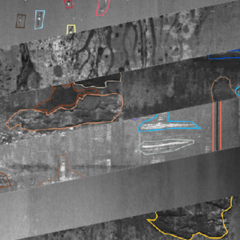

Severstal is leading the charge in efficient steel mining and production. They believe the future of metallurgy requires development across the economic, ecological, and social aspects of the industry—and they take corporate responsibility seriously. The company recently created the country’s largest industrial data lake, with petabytes of data that were previously discarded. Severstal is now looking to machine learning to improve automation, increase efficiency, and maintain high quality in their production.

The production process of flat sheet steel is especially delicate. From heating and rolling, to drying and cutting, several machines touch flat steel by the time it’s ready to ship. Today, Severstal uses images from high frequency cameras to power a defect detection algorithm.

In this competition, you’ll help engineers improve the algorithm by localizing and classifying surface defects on a steel sheet.

If successful, you’ll help keep manufacturing standards for steel high and enable Severstal to continue their innovation, leading to a stronger, more efficient world all around us.

## 1. Dataset Description

In this competition you will be predicting the location and type of defects found in steel manufacturing. Images are named with a unique **ImageId**. You must segment and classify the defects in the test set.

Each image may have no defects, a defect of a single class, or defects of multiple classes. For each image you must segment defects of each class (`ClassId = [1, 2, 3, 4]`).

The segment for each defect class will be encoded into a single row, even if there are several non-contiguous defect locations on an image. You can read more about the encoding standard on the Evaluation page.

Submissions to this competition must be made through Kernels. After your submission against the Public test set, your kernel will re-run automatically against the entire Public and Private (unseen) test set. Refer to the Kernels Requirement Page for more information.

**Files**
- train_images/ - folder of training images
- test_images/ - folder of test images (you are segmenting and classifying these images)
- train.csv - training annotations which provide segments for defects (`ClassId = [1, 2, 3, 4]`)
- sample_submission.csv - a sample submission file in the correct format; note, each ImageId 4 rows, one for each of the 4 defect classes

### Github
https://github.com/gA4ss/severstal-steel-defect-detection.git

## 2. DataView

In [5]:
from data_exploration import SteelDefectDataExplorer

In [6]:
explorer = SteelDefectDataExplorer()

Loading data...
Training data loaded: 7095 records
Sample submission file loaded: 5506 records


In [7]:
explorer.explore_data_structure()

Explore data structure

1. Training data basic information:
   - Data shape: (7095, 3)
   - Column names: ['ImageId', 'ClassId', 'EncodedPixels']
   - Data types:
ImageId          object
ClassId           int64
EncodedPixels    object
dtype: object

2. Training data first 5 rows:
         ImageId  ClassId                                      EncodedPixels
0  0002cc93b.jpg        1  29102 12 29346 24 29602 24 29858 24 30114 24 3...
1  0007a71bf.jpg        3  18661 28 18863 82 19091 110 19347 110 19603 11...
2  000a4bcdd.jpg        1  37607 3 37858 8 38108 14 38359 20 38610 25 388...
3  000f6bf48.jpg        4  131973 1 132228 4 132483 6 132738 8 132993 11 ...
4  0014fce06.jpg        3  229501 11 229741 33 229981 55 230221 77 230468...
ImageId          0
ClassId          0
EncodedPixels    0
dtype: int64

4. Unique value statistics:
   - Unique image count: 6666
   - Defect classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

5. Sample submission file information:
   - Data shap

In [8]:
explorer.explore_defect_distribution()


Defect distribution analysis

1. Defect count distribution:
   - Defect class 1: 897 defects
   - Defect class 2: 247 defects
   - Defect class 3: 5150 defects
   - Defect class 4: 801 defects

2. Defect image statistics:
   - Total image count: 6666
   - Defective image count: 6666
   - Defective image ratio: 100.00%

3. Defect count per image:
ClassId
1    6239
2     425
3       2
Name: count, dtype: int64


(ClassId
 1     897
 2     247
 3    5150
 4     801
 Name: count, dtype: int64,
 ImageId
 0002cc93b.jpg    1
 0007a71bf.jpg    1
 000a4bcdd.jpg    1
 000f6bf48.jpg    1
 0014fce06.jpg    1
                 ..
 ffcf72ecf.jpg    1
 fff02e9c5.jpg    1
 fffe98443.jpg    1
 ffff4eaa8.jpg    1
 ffffd67df.jpg    1
 Name: ClassId, Length: 6666, dtype: int64)

In [9]:
_ , _ = explorer.explore_image_properties()


Image property analysis

1. Image file statistics:
   - Training image count: 12568
   - Test image count: 5506

2. Analyzing 100 sample images...

3. Image dimension statistics:
   - Width range: 1600 - 1600
   - Height range: 256 - 256
   - Most common dimension: (1600, 256)

4. Pixel value statistics:
   - Mean pixel value range: 10.85 - 171.56
   - Pixel value standard deviation range: 14.16 - 90.46


In [12]:
_ = explorer.analyze_defect_sizes()


Defect size analysis
Analyzing 500 defect samples...

Defect size statistics (pixels):
Defect class 1:
   - Number of defects: 64
   - Mean size: 4160
   - Median size: 3000
   - Size range: 449 - 15120
Defect class 2:
   - Number of defects: 17
   - Mean size: 2635
   - Median size: 2471
   - Size range: 990 - 5799
Defect class 3:
   - Number of defects: 365
   - Mean size: 23532
   - Median size: 11146
   - Size range: 335 - 289556
Defect class 4:
   - Number of defects: 54
   - Mean size: 41630
   - Median size: 28144
   - Size range: 491 - 129794


In [13]:
explorer.generate_summary_report()


Data exploration summary report

Data set overview:
   * Total records: 7,095
   * Total images: 6,666
   * Defective records: 7,095
   * Defective images: 6,666
   * Defective image ratio: 100.0%

Defect class distribution:
   * Class 1: 897 (12.6%)
   * Class 2: 247 (3.5%)
   * Class 3: 5,150 (72.6%)
   * Class 4: 801 (11.3%)

Data quality assessment:
   * Defective records: 0
   * Data integrity: 100.0%

Recommendations:
   * Data set size is moderate, suitable for deep learning training
   * Defect distribution is imbalanced, consider class balance strategies
   * Suggest using data augmentation techniques to increase sample diversity


## 3. Features engineering

In [8]:
from eda_visualization import SteelDefectEDA


Generating exploratory data analysis report

1. Defect distribution analysis...
Generating defect distribution visualization...


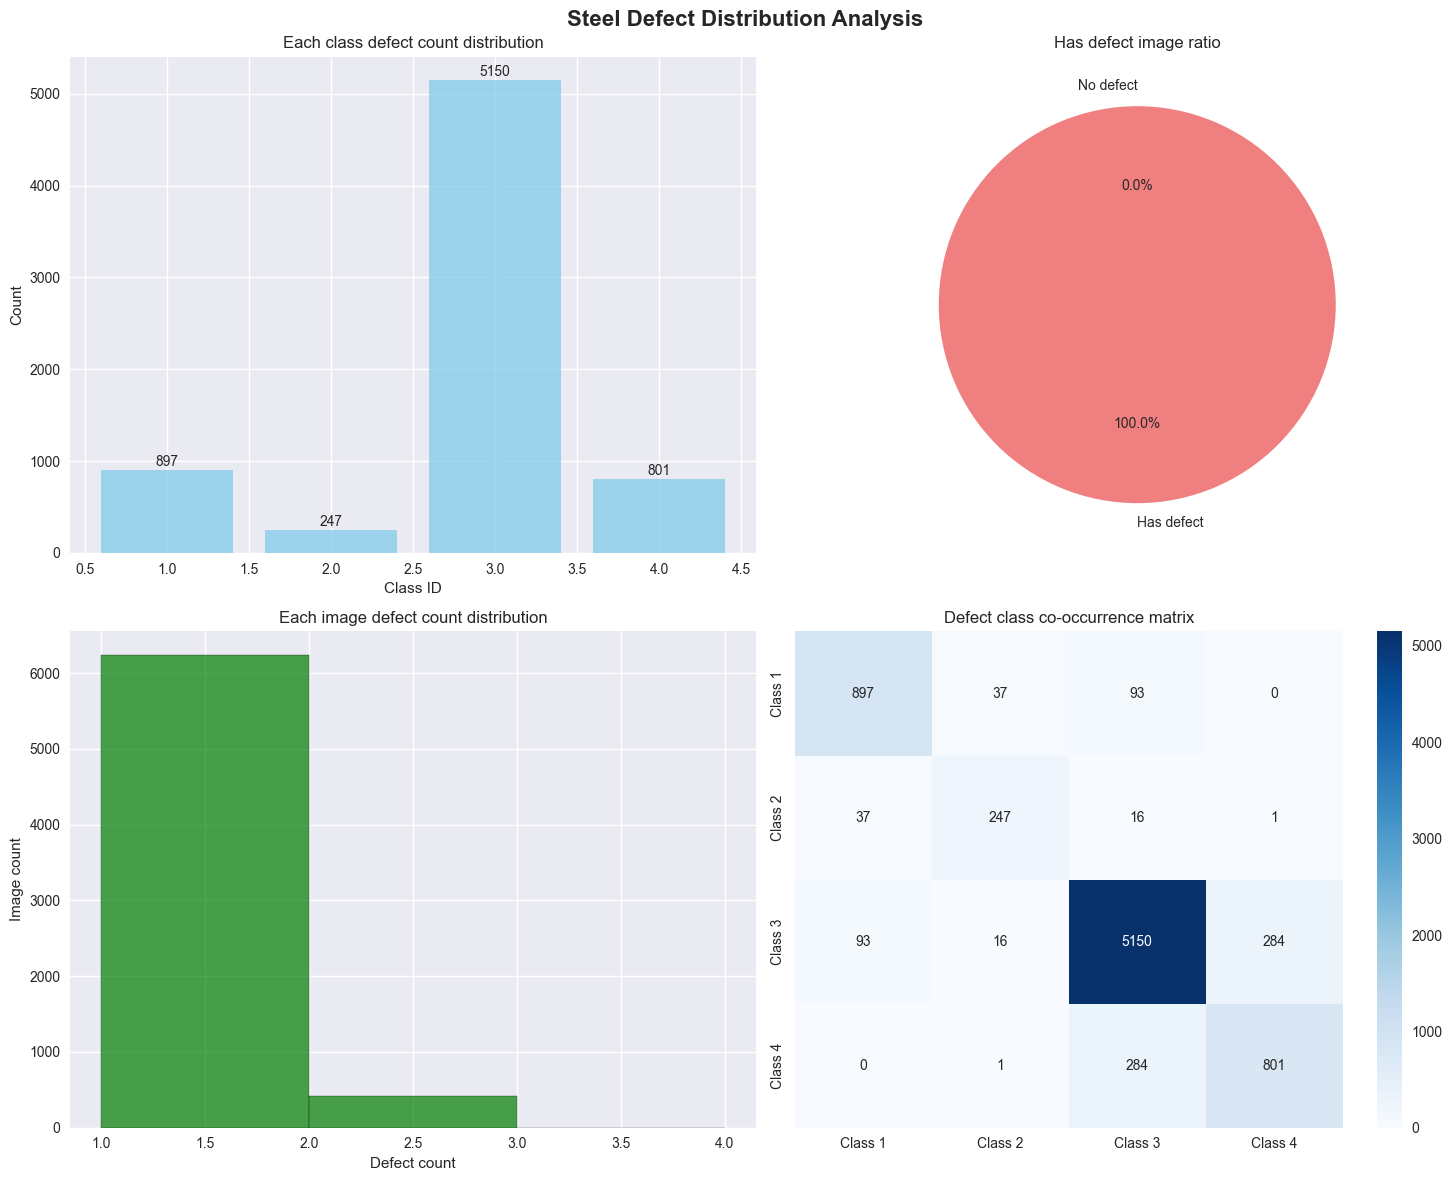


2. Defect size analysis...
Analyzing defect size distribution...


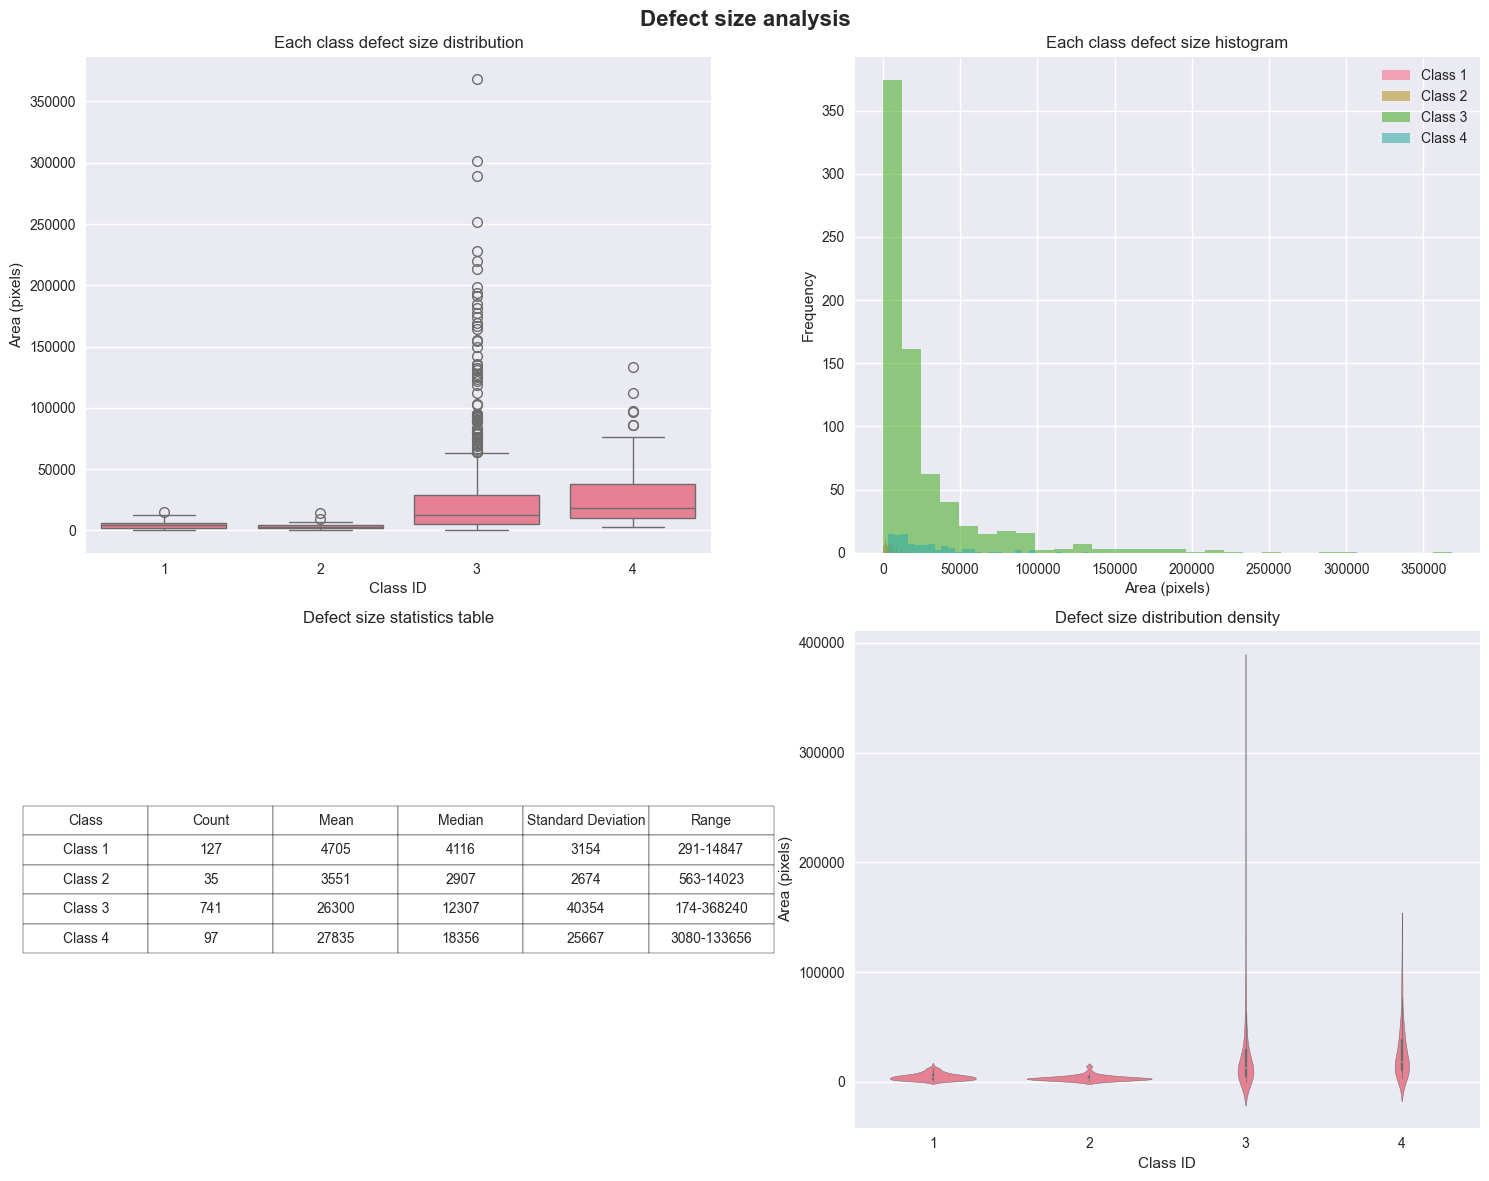


3. Sample image visualization...
Visualizing sample images and defect masks...


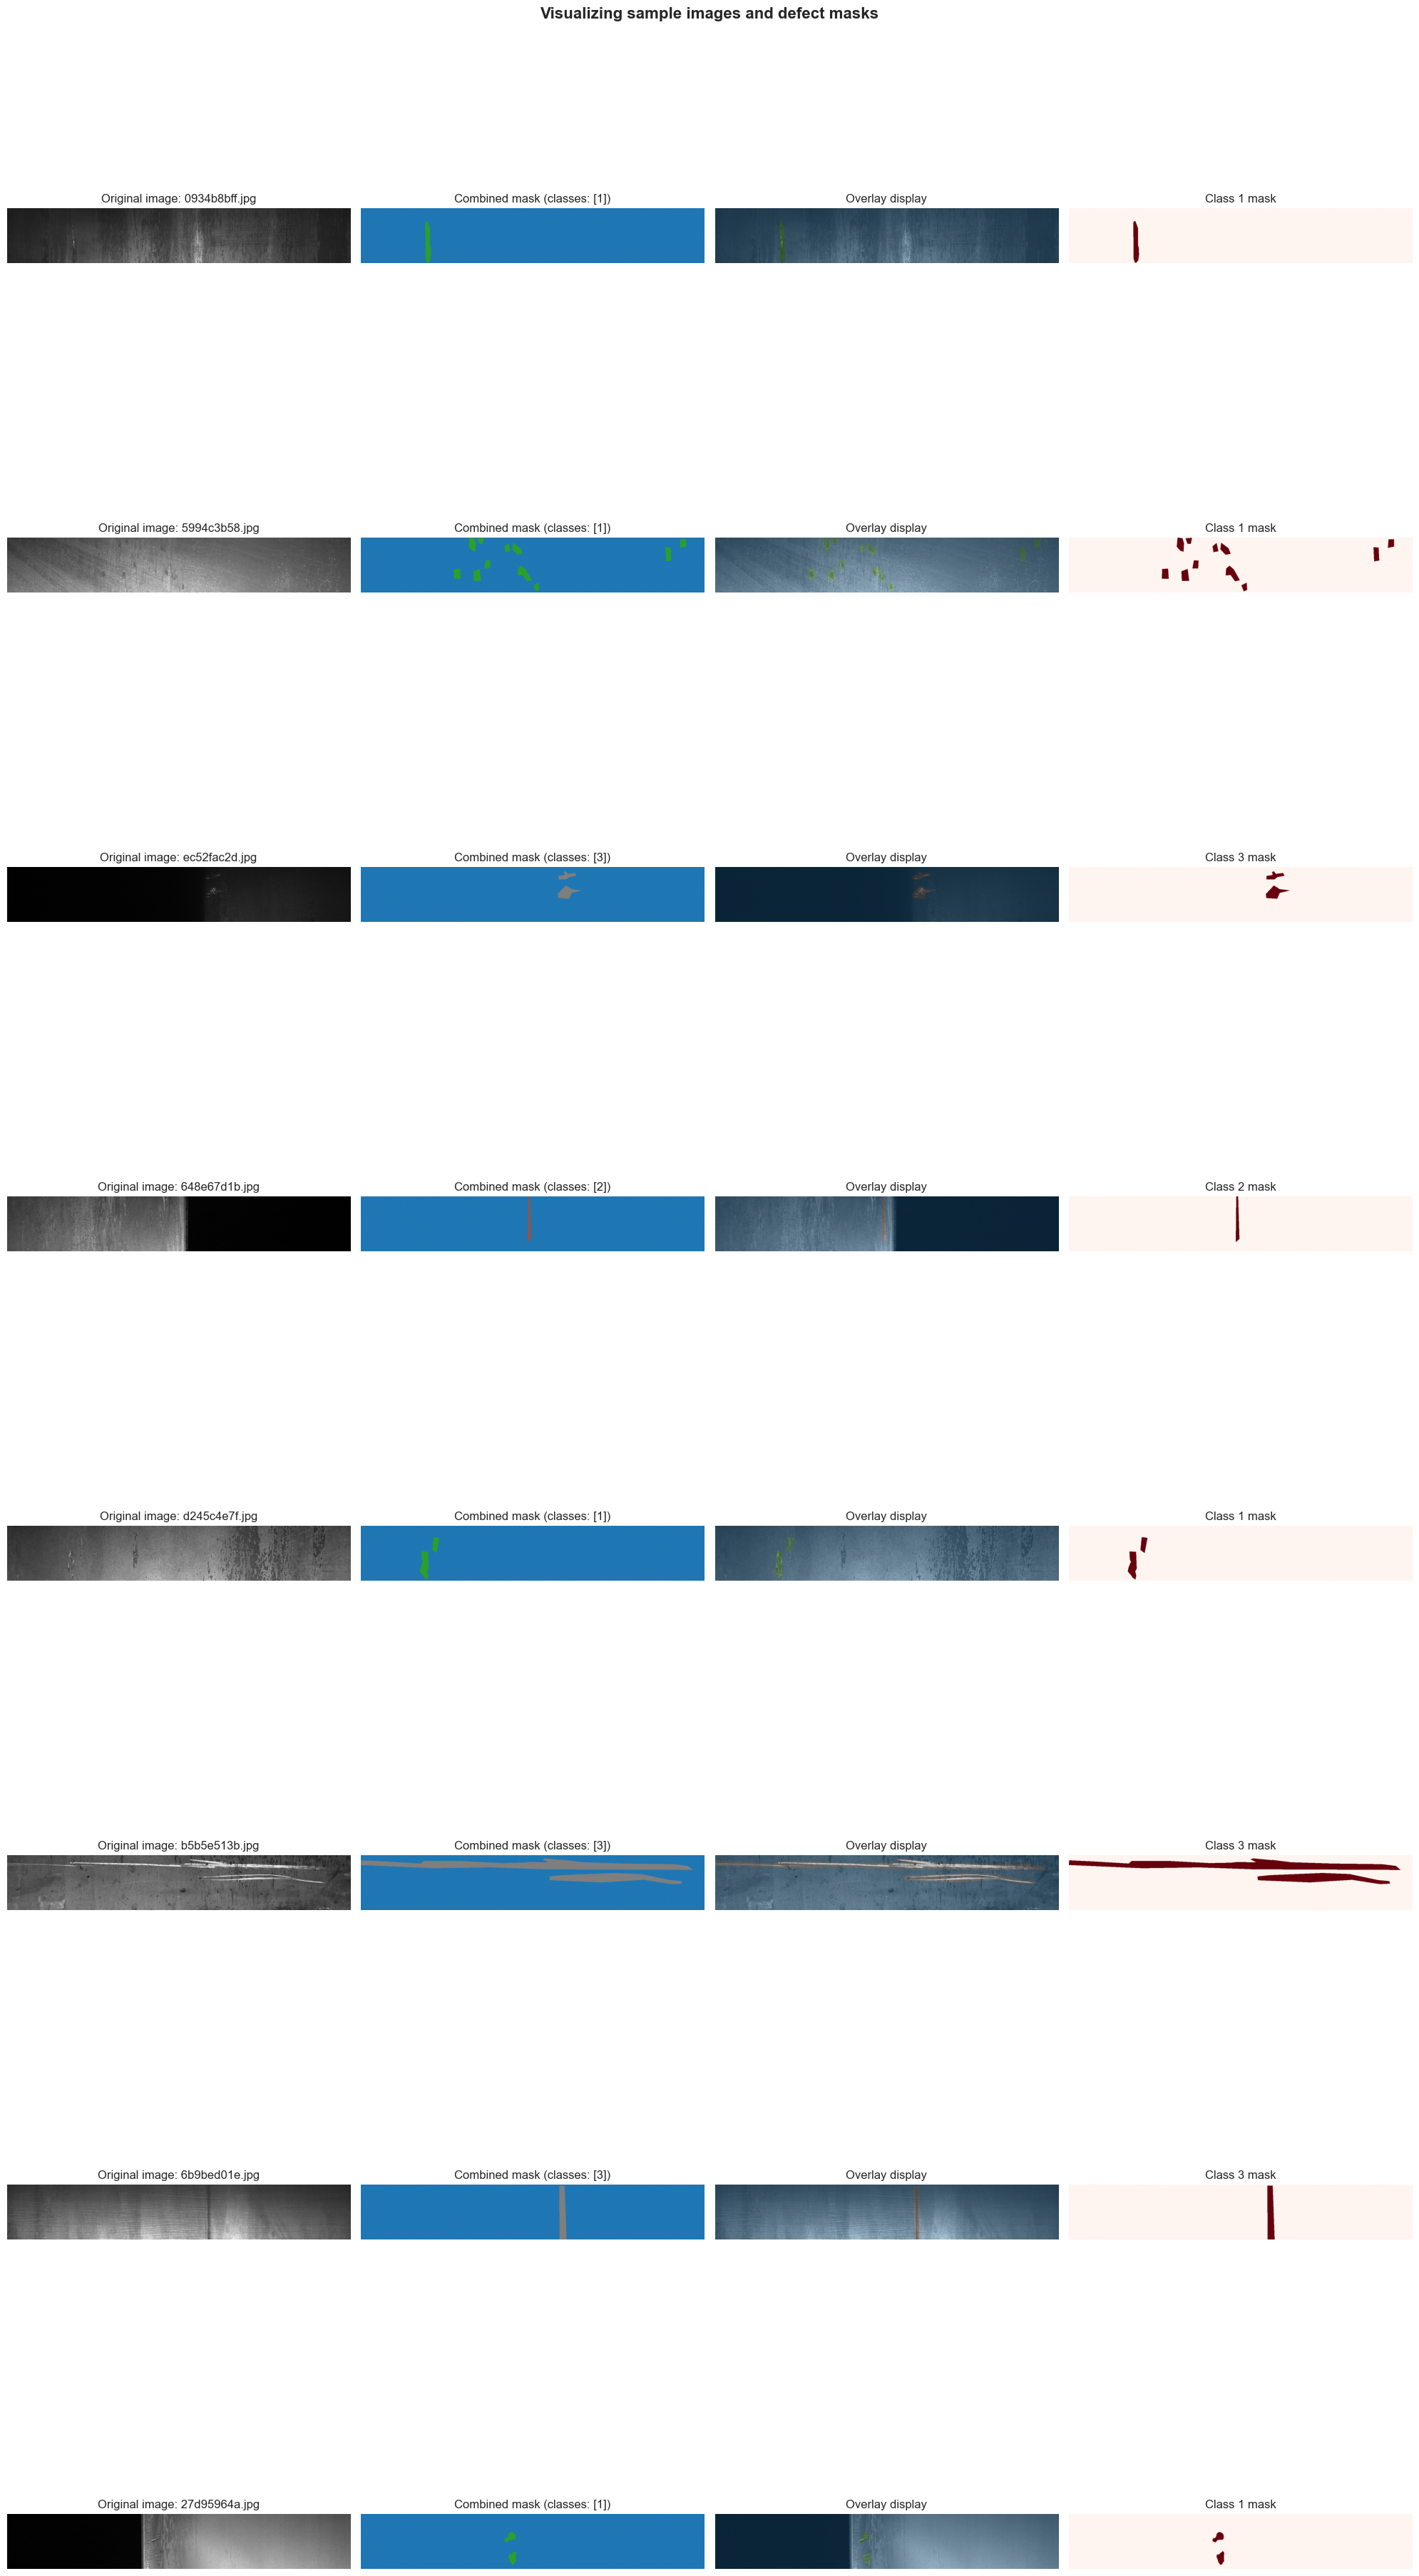


4. Image statistics analysis...
Analyzing image statistics...


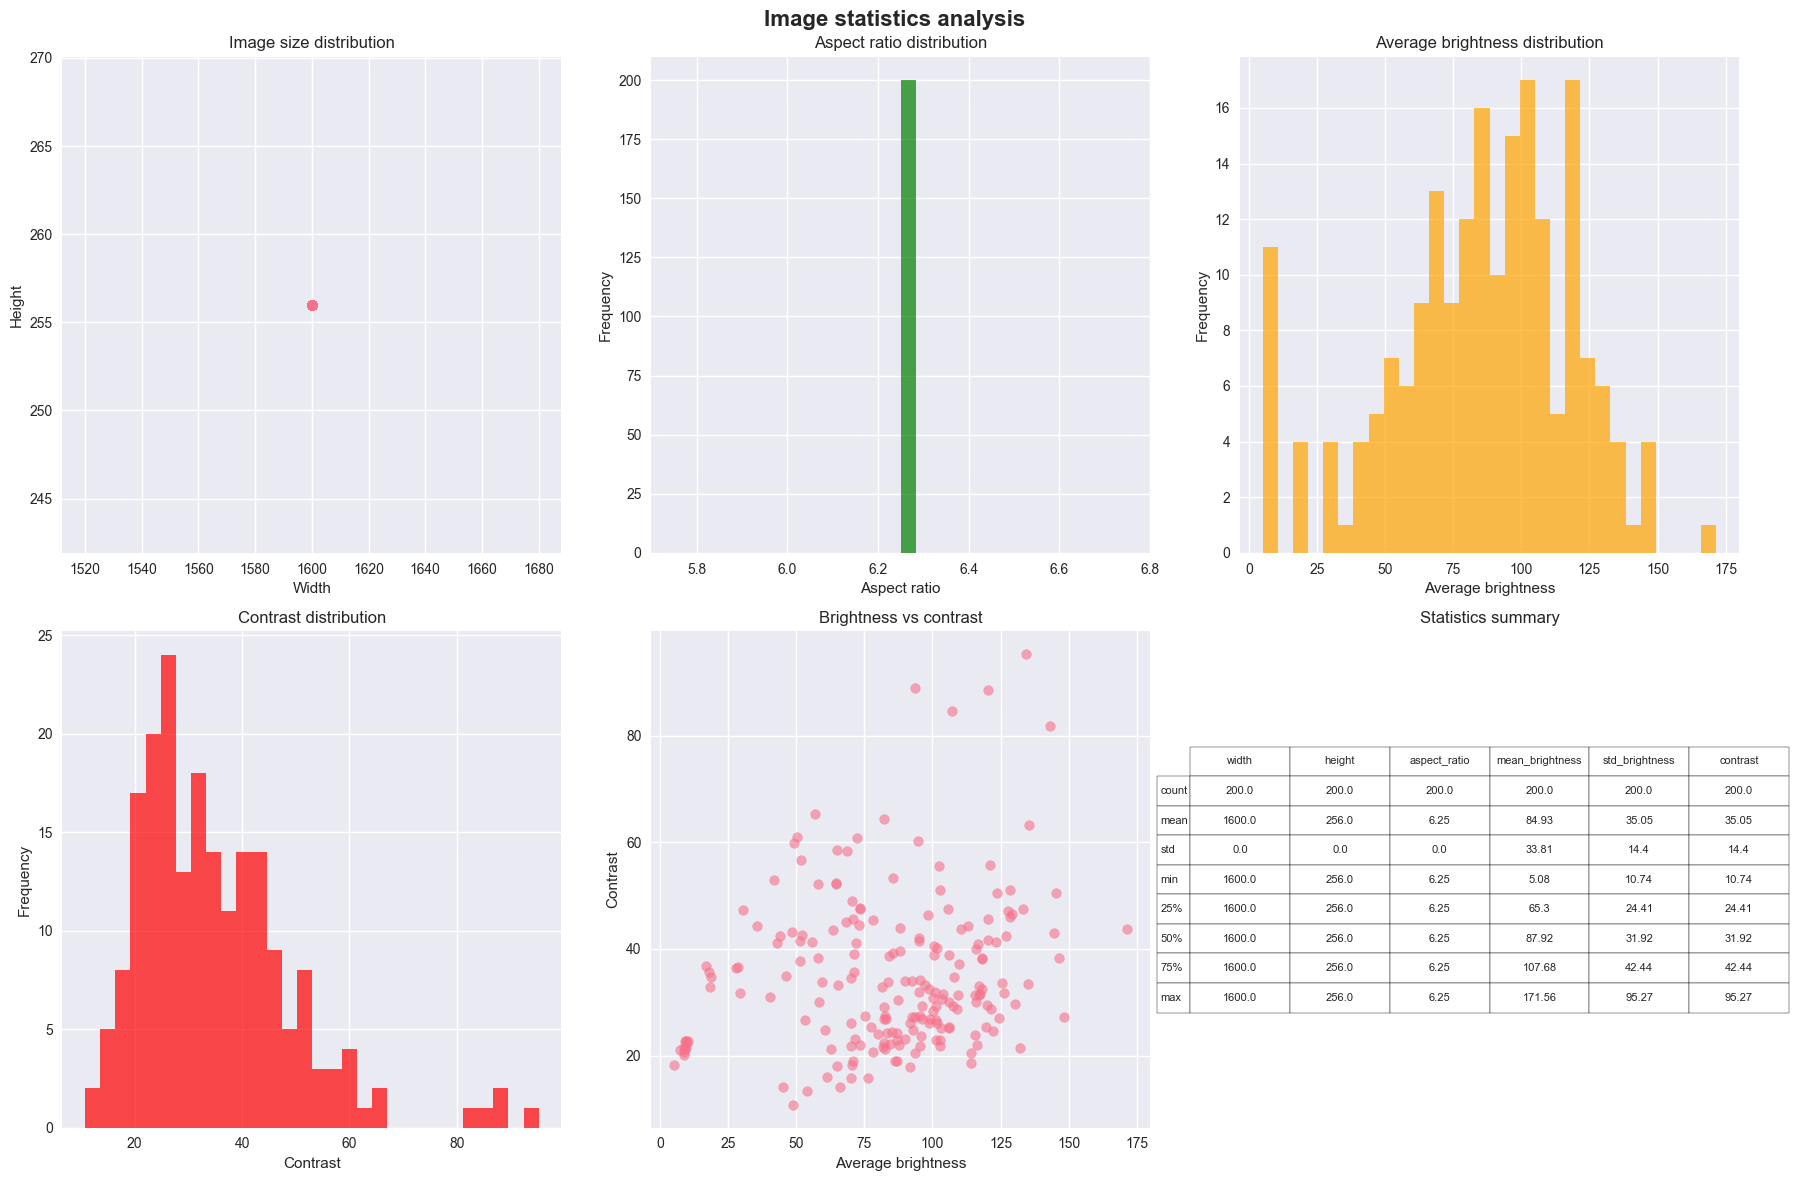


5. Interactive dashboard...
Creating interactive dashboard...
Interactive dashboard saved to: eda_outputs\interactive_dashboard.html

EDA report generated and saved to: eda_outputs
   - Chart files: eda_outputs/*.png
   - Interactive dashboard: eda_outputs/interactive_dashboard.html
   - Text report: eda_outputs\eda_report.txt


In [10]:
eda = SteelDefectEDA()
eda.generate_eda_report()

## 4. Data Preprocessing

In [ ]:
from data_preprocessing import SteelDefectPreprocessor()

In [ ]:
preprocessor = SteelDefectPreprocessor()
preprocessor.generate_preprocessing_report()   

### Steel Defect Detection - Data Preprocessing Report

**======================================================**                      

### Data quality assessment:
   - Total records: 7,095
   - Unique images: 6,666
   - RLE encoding validation: PASS
   - Missing image files: 0

### Defect distribution:
   - Class 1: 897
   - Class 2: 247
   - Class 3: 5,150
   - Class 4: 801

### Data split:
   - Training images: 5332
   - Test images: 1334
   - Cross-validation folds: 5

### Defect feature analysis:
   * Class 1:
     - Count: 897
     - Average area: 4502 pixels
     - Average aspect ratio: 0.52
   * Class 2:
     - Count: 247
     - Average area: 3378 pixels
     - Average aspect ratio: 0.13
   * Class 3:
     - Count: 5150
     - Average area: 24879 pixels
     - Average aspect ratio: 1.02
   * Class 4:
     - Count: 801
     - Average area: 32278 pixels
     - Average aspect ratio: 1.76


## 5. Training model

I used U-NET++ as the base model and used transfer learning on it to train. **Here are some introductions to U-NET++ from the Internet.**

## U-Net++ Architecture Overview

**U-Net++** (UNet Plus Plus) is an advanced medical image segmentation network architecture proposed by Zhou et al. in 2018, representing a significant improvement over the classic U-Net. It dramatically enhances segmentation accuracy and feature representation capabilities through nested and dense skip connections.

### Core Architecture Features

1. **Nested U-Net Structure**:
   - Traditional U-Net has only one U-shaped path
   - U-Net++ contains multiple nested U-shaped sub-networks
   - Forms a densely connected pyramid structure

2. **Redesigned Skip Connections**:
   - Traditional U-Net uses simple feature concatenation
   - U-Net++ employs dense convolutional blocks connecting encoder and decoder
   - Reduces semantic gap between encoder and decoder feature maps

3. **Deep Supervision Mechanism**:
   - Adds auxiliary loss functions at different depth levels
   - Provides richer gradient information
   - Accelerates convergence and improves segmentation accuracy

### Technical Advantages

```
Encoder Features → Dense Skip Connections → Decoder Features
       ↓                    ↓                    ↓
  Shallow Details → Multi-scale Fusion → Fine Segmentation
       ↓                    ↓                    ↓
   Deep Semantics → Context Understanding → Accurate Localization
```

## Rationale for Choosing U-Net++ in Steel Defect Detection Project

### 1. Unique Challenges in Defect Segmentation

Steel surface defect detection faces the following technical challenges:

- **Multi-scale Defects**: From tiny scratches to large oxidation patches
- **Blurred Boundaries**: Unclear boundaries between defective and normal areas
- **Class Imbalance**: Defective regions occupy extremely small proportions (typically <5%)
- **Complex Background**: Complex and variable steel surface textures

### 2. Targeted Advantages of U-Net++

**Multi-scale Feature Fusion**:
```python
# U-Net++'s dense connections can capture defect features at different scales
class UNetPlusPlus(nn.Module):
    def __init__(self, encoder_name='efficientnet-b4'):
        # Nested U-shaped structure, suitable for multi-scale defect detection
        self.model = smp.UnetPlusPlus(
            encoder_name=encoder_name,
            encoder_weights='imagenet',
            classes=4,  # 4 defect types
            activation=None
        )
```

**Precise Boundary Localization**:
- Dense skip connections preserve more spatial detail information
- Suitable for detecting surface defects with blurred boundaries
- Reduces missed detection of small target defects

**Deep Supervised Learning**:
- Multi-level loss functions alleviate class imbalance issues
- Provides more stable gradient updates
- Accelerates model convergence

### 3. Comparative Advantages Over Other Models

| Model | Advantages | Limitations in Steel Defect Detection |
|-------|------------|--------------------------------------|
| **Classic U-Net** | Simple and efficient | Large semantic gap in skip connections, easy to lose small defects |
| **DeepLab** | Dilated convolution, large receptive field | Insufficient sensitivity to tiny defects |
| **PSPNet** | Pyramid pooling | Limited boundary localization accuracy |
| **U-Net++** | Dense connections + deep supervision | **Most suitable for fine segmentation tasks** |

### 4. Synergistic Effect with EfficientNet-B4 Encoder

```python
# Optimal configuration in the project
encoder_name = 'efficientnet-b4'  # Balance accuracy and efficiency
encoder_weights = 'imagenet'      # Pre-trained weights accelerate convergence
```

**Selection Rationale**:
- **Parameter Efficiency**: EfficientNet-B4 provides optimal accuracy/parameter ratio
- **Feature Richness**: Depthwise separable convolutions extract rich texture features
- **Transfer Learning**: ImageNet pre-trained weights adapt to industrial scenarios

**The above content is sourced from internet research materials.**

```python
from model_training import SteelDefectTrainer

# Create trainer
trainer = SteelDefectTrainer(config)  

# Start training
trainer.train(train_df, images_dir)

# Plot training history
trainer.plot_training_history()
```

Here, we do not directly conduct the training process. Instead, I have provided a script for training. The model requires a significant amount of time to train, and I employed U-NET++ as the base model upon which I performed transfer learning. The entire training process took approximately two days to complete. By the 51st epoch, the model's validation set Dice coefficient reached 0.83. However, training was interrupted at the 66th epoch due to an unknown error, causing an internal PyTorch error. Despite this, I felt that the model had already converged and would not significantly improve further, so I did not resume training. Subsequently, I adjusted the weights of the Dice and loss functions to a ratio of 0.8 and 0.2, respectively, as opposed to the previous setting of 0.7 and 0.3. My intention was to place greater emphasis on the Dice metric. Additionally, I implemented class weighting, assigning higher weights to samples of the less frequent defect types, aiming to bias the model towards better recognition of small sample errors. However, this change might have altered the model's parameters, resulting in a lower Dice coefficient on the validation set during subsequent training.


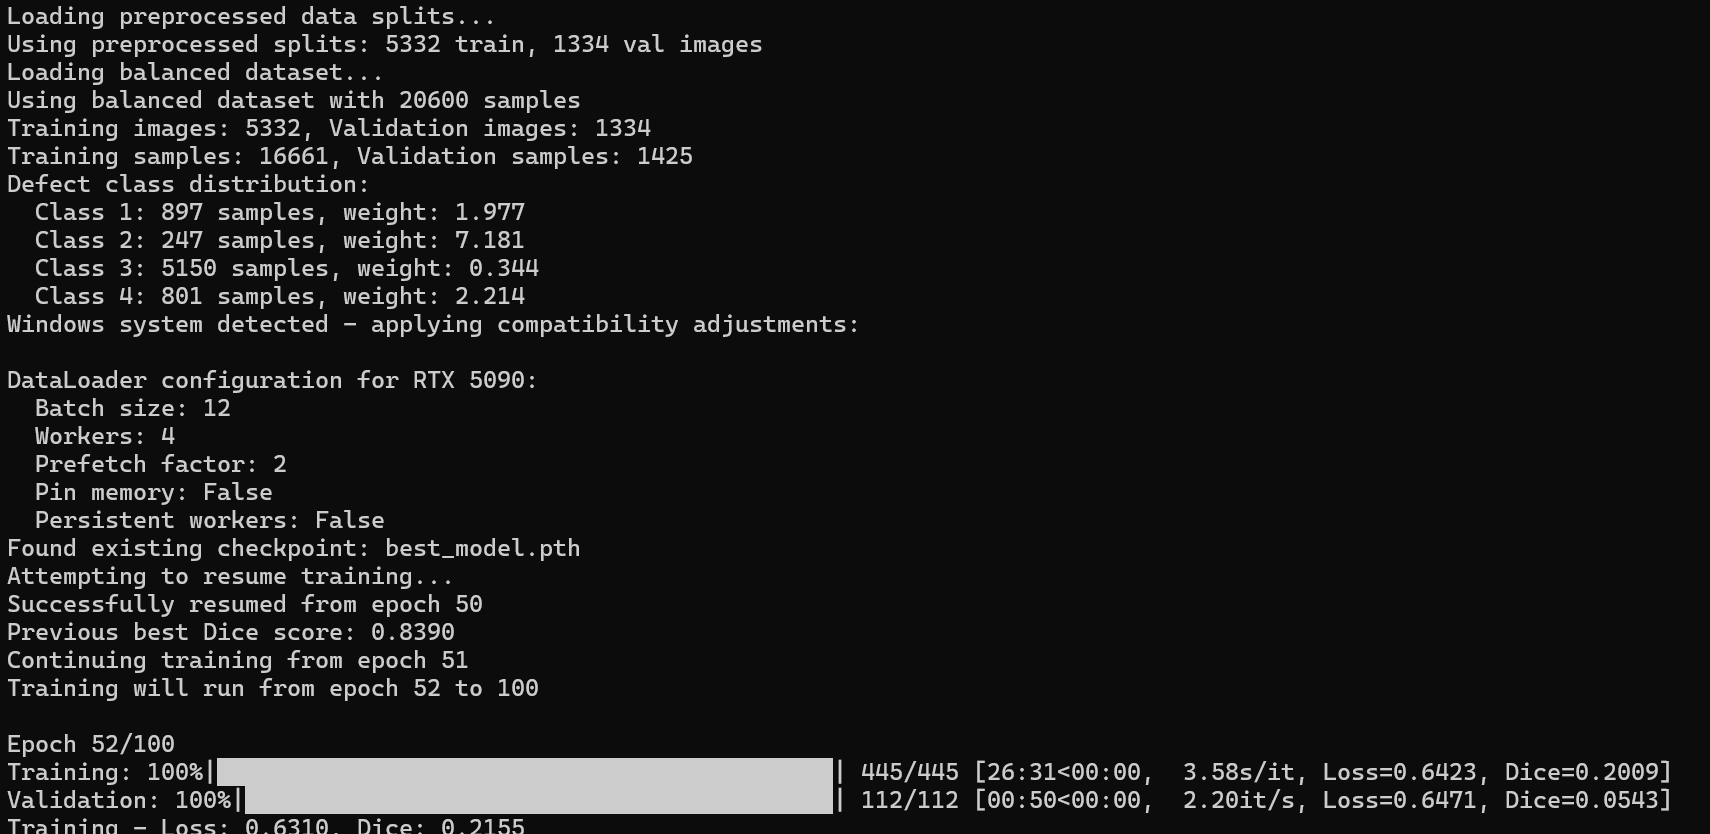

Therefore, I abandoned further training of the model and directly used the best-trained model available for prediction. The model has been saved to the Git repository and can be used directly.

## 6. Predict in test set

In [1]:
from model_predict import create_submission_from_test_dir, visualize_sample_predictions

In [2]:
create_submission_from_test_dir(
    test_dir='./data/test_images',
    checkpoint_path='best_model.pth',
    output_path='submission.csv',
    threshold=0.4,
    tta=True,
    batch_size=4
)

Found 5506 test images
Loading model from: best_model.pth
Model loaded successfully from epoch 50
Best validation Dice: 0.8390
Submission saved to: submission.csv
Total predictions: 22024
Images with defects: 9936/22024 (45.1%)


'submission.csv'

Visualizing 4 sample test images with submission predictions...
Loaded submission file with 22024 predictions
Visualization saved to: test_predictions_visualization.png


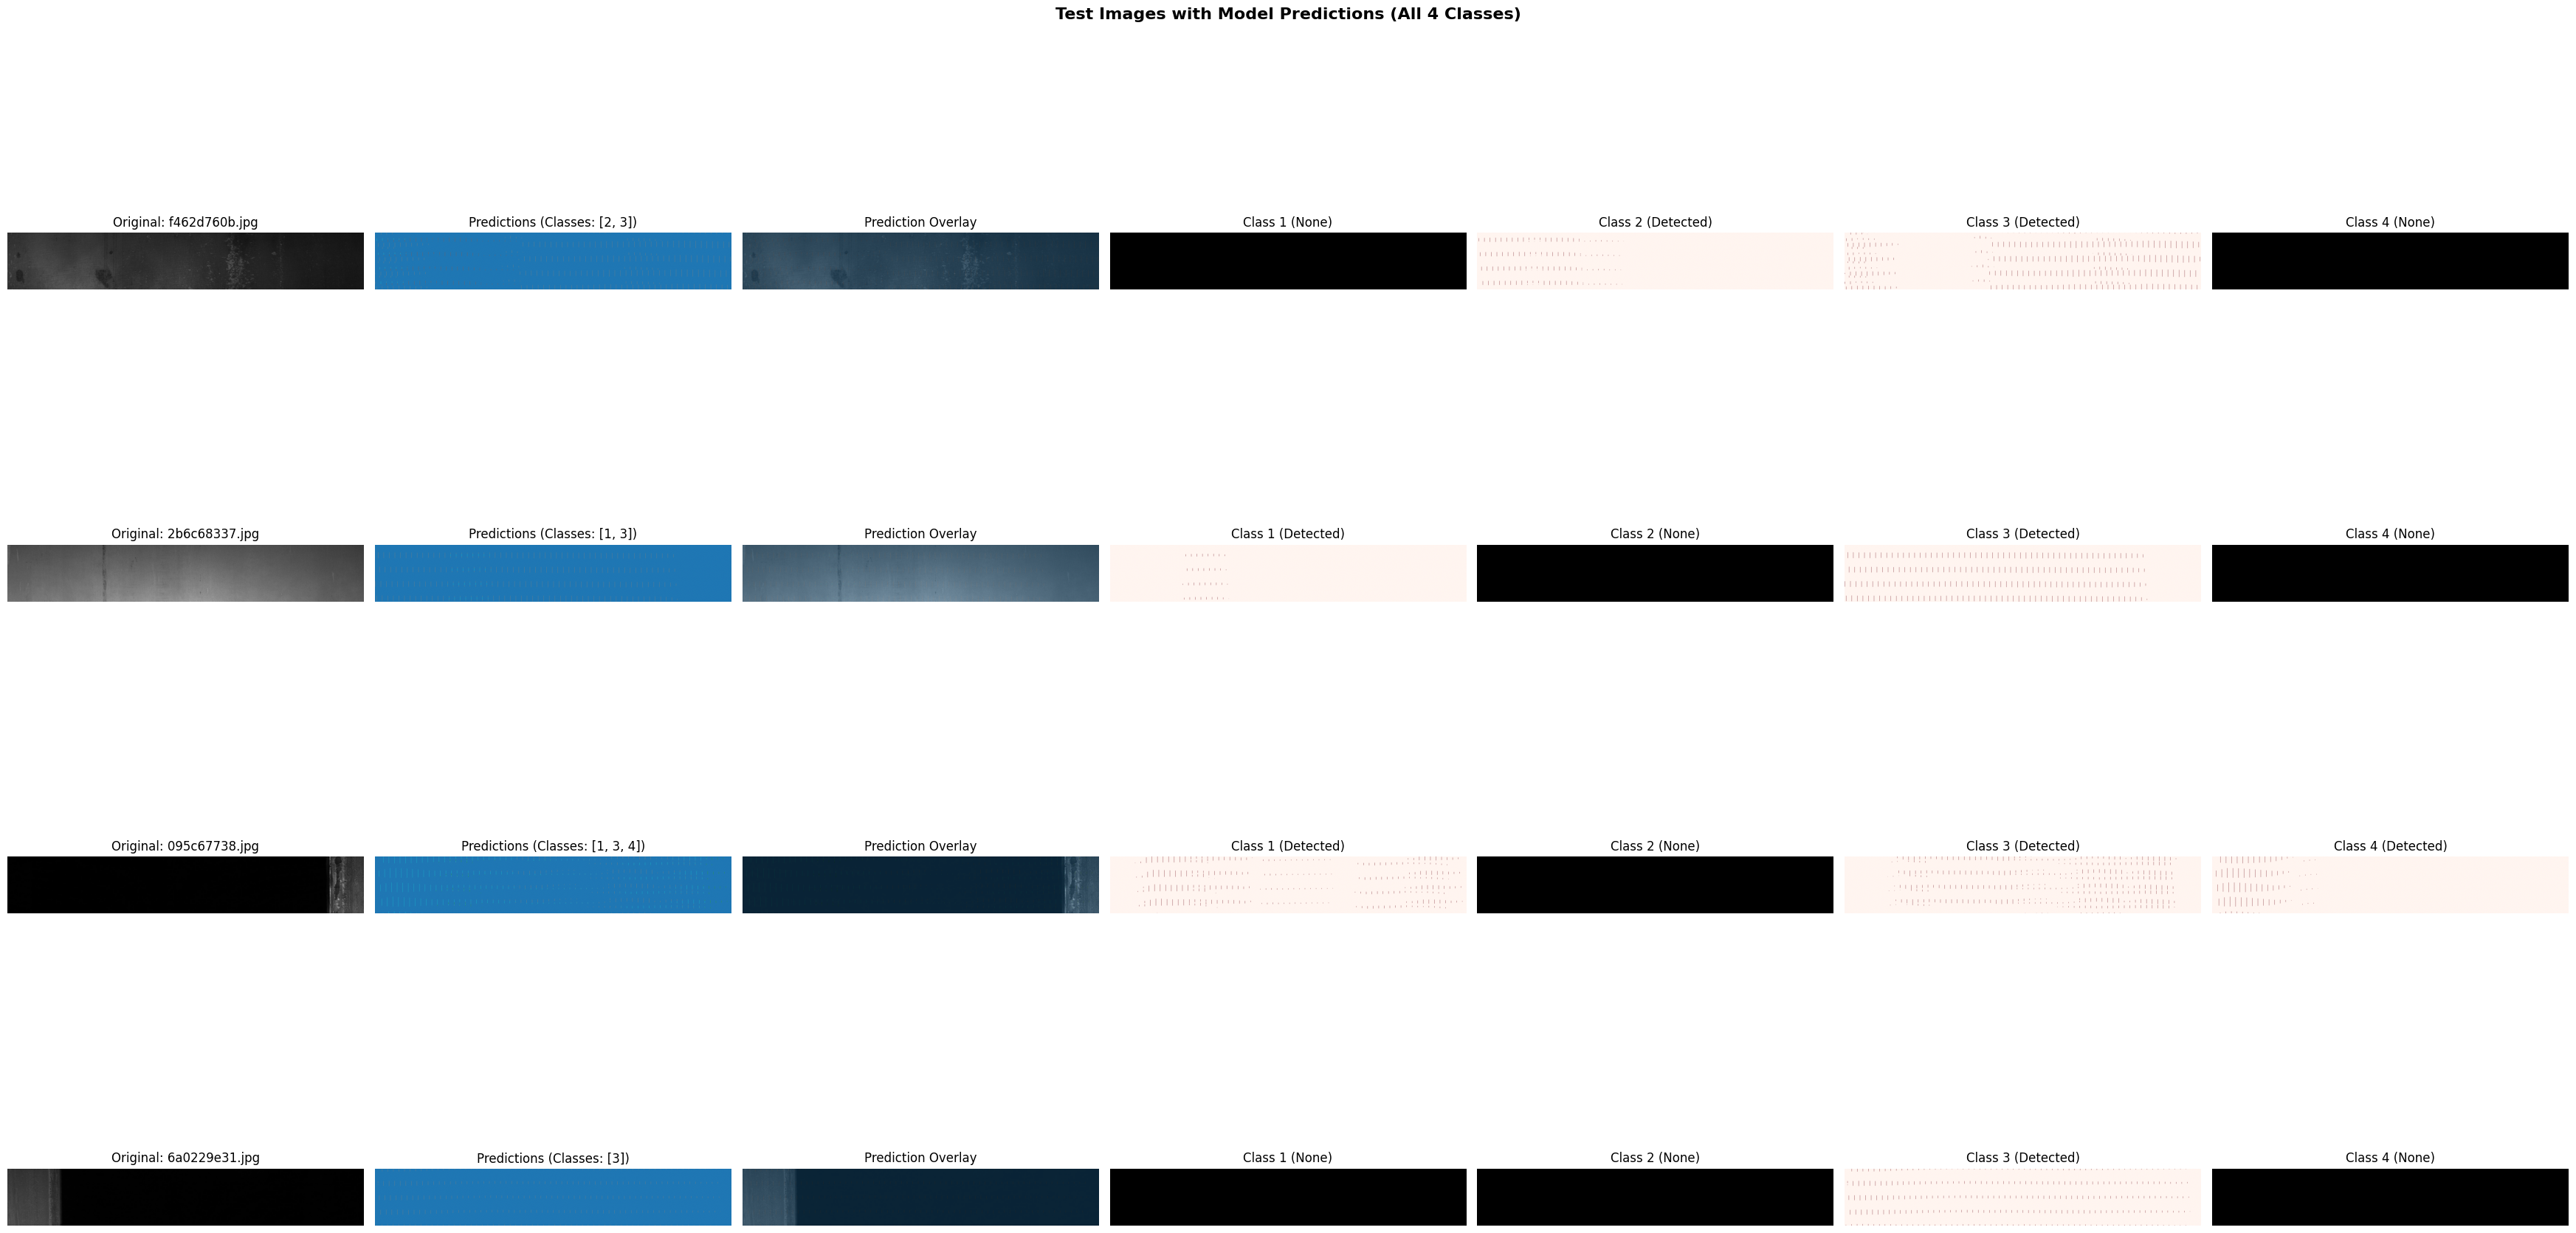

'test_predictions_visualization.png'

In [3]:
visualize_sample_predictions(
    test_dir='./data/test_images',
    submission_csv='./submission.csv',
    output_dir='.',
    num_samples=4
)